<a href="https://colab.research.google.com/github/ShreyaBawankar77/Hack-O-Week/blob/main/Car_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
uploaded = files.upload()

Saving archive (2).zip to archive (2).zip


In [ ]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/car_data')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
for root, dirs, files_list in os.walk('/content/car_data'):
    for file in files_list:
        print(os.path.join(root, file))

/content/car_data/housing_cleaned.csv


In [ ]:
df = pd.read_csv('/content/car_data/housing_cleaned.csv')

print("Dataset loaded successfully!")
print("Rows and Columns:", df.shape)

Dataset loaded successfully!
Rows and Columns: (12000, 4)


In [ ]:
df.head()

,price,bhk,area_sqft,parking
0,9500000.0,3.0,1400.0,0.0
1,57500000.0,3.0,1400.0,0.0
2,4000000.0,3.0,1400.0,0.0
3,13800000.0,4.0,1400.0,0.0
4,11000000.0,4.0,1400.0,0.0


In [ ]:
df.describe()

,price,bhk,area_sqft,parking
count,1.200000e+04,12000.000000,12000.000000,12000.000000
mean,3.153475e+07,3.089917,1640.961417,0.691583
std,5.002292e+07,0.932597,2229.662233,0.461859
min,7.500000e+05,1.000000,32.000000,0.000000
25%,7.700000e+06,3.000000,900.000000,0.000000
50%,1.865000e+07,3.000000,1400.000000,1.000000
75%,3.470000e+07,4.000000,1900.000000,1.000000
max,1.500000e+09,12.000000,109000.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   price      12000 non-null  float64
 1   bhk        12000 non-null  float64
 2   area_sqft  12000 non-null  float64
 3   parking    12000 non-null  float64
dtypes: float64(4)
memory usage: 375.1 KB


In [ ]:
print(df.isnull().sum())

price        0
bhk          0
area_sqft    0
parking      0
dtype: int64


In [ ]:
df.describe()

,price,bhk,area_sqft,parking
count,1.200000e+04,12000.000000,12000.000000,12000.000000
mean,3.153475e+07,3.089917,1640.961417,0.691583
std,5.002292e+07,0.932597,2229.662233,0.461859
min,7.500000e+05,1.000000,32.000000,0.000000
25%,7.700000e+06,3.000000,900.000000,0.000000
50%,1.865000e+07,3.000000,1400.000000,1.000000
75%,3.470000e+07,4.000000,1900.000000,1.000000
max,1.500000e+09,12.000000,109000.000000,1.000000


In [ ]:
data = df[
    [
        'price',
        'bhk',
        'area_sqft',
        'parking'
    ]
].copy()

data.head()

,price,bhk,area_sqft,parking
0,9500000.0,3.0,1400.0,0.0
1,57500000.0,3.0,1400.0,0.0
2,4000000.0,3.0,1400.0,0.0
3,13800000.0,4.0,1400.0,0.0
4,11000000.0,4.0,1400.0,0.0


In [ ]:
# All columns are already numeric (float64) in the housing dataset,
# so explicit conversion is not necessary.
print(data.dtypes)

price        float64
bhk          float64
area_sqft    float64
parking      float64
dtype: object


In [ ]:
data = data.dropna()

print("Final dataset shape:", data.shape)
print("Missing values:")
print(data.isnull().sum())

Final dataset shape: (12000, 5)
Missing values:
price             0
bhk               0
area_sqft         0
parking           0
price_category    0
dtype: int64


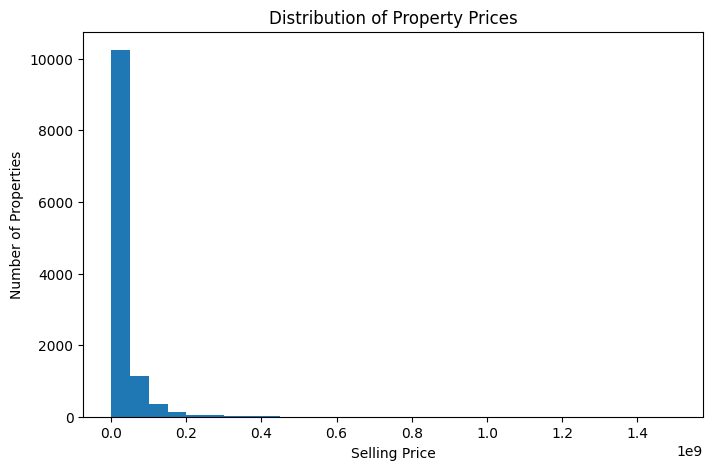

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(data['price'], bins=30)

plt.xlabel("Selling Price")
plt.ylabel("Number of Properties")
plt.title("Distribution of Property Prices")

plt.show()

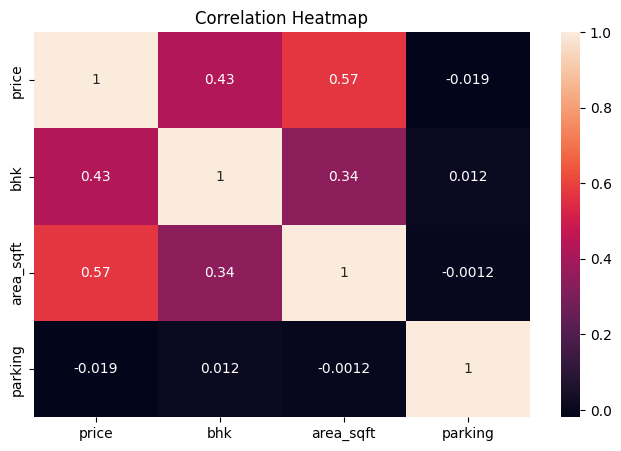

In [ ]:
plt.figure(figsize=(8,5))

correlation = data.select_dtypes(include=np.number).corr()

sns.heatmap(correlation, annot=True)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
X = data.drop('price', axis=1)
y = data['price']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (9600, 3)
Testing data: (2400, 3)


In [ ]:
categorical_features = [
    'parking'
]

numerical_features = [
    'bhk',
    'area_sqft'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            StandardScaler(),
            numerical_features
        )
    ]
)

In [ ]:
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("LINEAR REGRESSION")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)

LINEAR REGRESSION
MAE : 17177757.852923233
RMSE: 30602511.314735774
R2 Score: 0.458669012395584


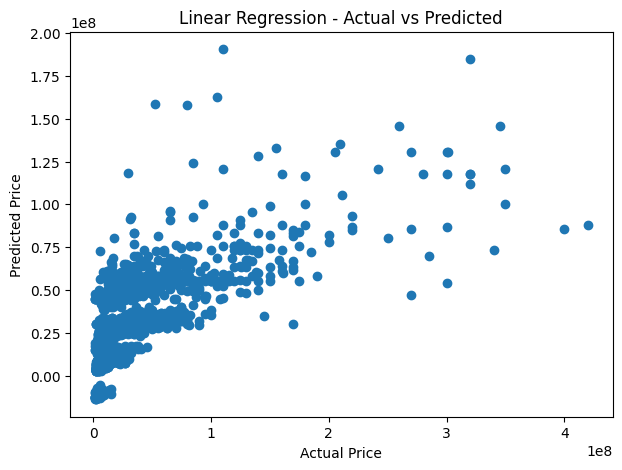

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(y_test, linear_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Linear Regression - Actual vs Predicted")

plt.show()

In [ ]:
poly_features = [
    'bhk',
    'area_sqft'
]

X_poly = data[poly_features]
y_poly = data['price']

X_poly_train, X_poly_test, y_poly_train, y_poly_test = train_test_split(
    X_poly,
    y_poly,
    test_size=0.2,
    random_state=42
)

poly_model = Pipeline([
    ('poly', PolynomialFeatures(degree=2)),
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

poly_model.fit(X_poly_train, y_poly_train)

poly_pred = poly_model.predict(X_poly_test)

poly_mae = mean_absolute_error(y_poly_test, poly_pred)
poly_rmse = np.sqrt(mean_squared_error(y_poly_test, poly_pred))
poly_r2 = r2_score(y_poly_test, poly_pred)

print("POLYNOMIAL REGRESSION")
print("MAE :", poly_mae)
print("RMSE:", poly_rmse)
print("R2 Score:", poly_r2)

POLYNOMIAL REGRESSION
MAE : 12349930.785188008
RMSE: 23681068.851566076
R2 Score: 0.6758460225253955


In [ ]:
ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

print("RIDGE REGRESSION")
print("MAE :", ridge_mae)
print("RMSE:", ridge_rmse)
print("R2 Score:", ridge_r2)

RIDGE REGRESSION
MAE : 17177871.67782926
RMSE: 30602989.58763313
R2 Score: 0.4586520918258731


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Lasso

categorical_features = [
    'parking'
]

numerical_features = [
    'bhk',
    'area_sqft'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            StandardScaler(),
            numerical_features
        )
    ]
)

lasso_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Lasso(alpha=0.1, max_iter=10000))
])

lasso_model.fit(X_train, y_train)

lasso_pred = lasso_model.predict(X_test)

lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))
lasso_r2 = r2_score(y_test, lasso_pred)

print("LASSO REGRESSION")
print("MAE :", lasso_mae)
print("RMSE:", lasso_rmse)
print("R2 Score:", lasso_r2)

LASSO REGRESSION
MAE : 17177757.865101855
RMSE: 30602511.34087101
R2 Score: 0.45866901147096617


In [ ]:
regression_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Polynomial Regression',
        'Ridge Regression',
        'Lasso Regression'
    ],
    'MAE': [
        linear_mae,
        poly_mae,
        ridge_mae,
        lasso_mae
    ],
    'RMSE': [
        linear_rmse,
        poly_rmse,
        ridge_rmse,
        lasso_rmse
    ],
    'R2 Score': [
        linear_r2,
        poly_r2,
        ridge_r2,
        lasso_r2
    ]
})

regression_results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.717776e+07,3.060251e+07,0.458669
1,Polynomial Regression,1.234993e+07,2.368107e+07,0.675846
2,Ridge Regression,1.717787e+07,3.060299e+07,0.458652
3,Lasso Regression,1.717776e+07,3.060251e+07,0.458669


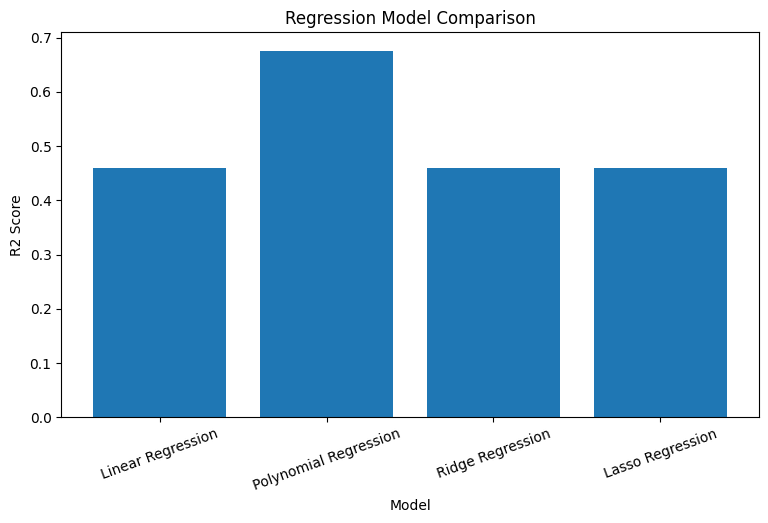

In [ ]:
plt.figure(figsize=(9,5))

plt.bar(
    regression_results['Model'],
    regression_results['R2 Score']
)

plt.ylabel("R2 Score")
plt.xlabel("Model")
plt.title("Regression Model Comparison")

plt.xticks(rotation=20)

plt.show()

In [ ]:
median_price = data['price'].median()

data['price_category'] = np.where(
    data['price'] >= median_price,
    'High Price',
    'Low Price'
)

print("Median Price:", median_price)

print(data['price_category'].value_counts())

Median Price: 18650000.0
price_category
Low Price     6000
High Price    6000
Name: count, dtype: int64


In [ ]:
X_class = data.drop(
    ['price', 'price_category'],
    axis=1
)

y_class = data['price_category']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Training:", X_train_c.shape)
print("Testing:", X_test_c.shape)

Training: (9600, 3)
Testing: (2400, 3)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

categorical_features = [
    'parking'
]

numerical_features = [
    'bhk',
    'area_sqft'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            StandardScaler(),
            numerical_features
        )
    ]
)

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=2000))
])

logistic_model.fit(X_train_c, y_train_c)

logistic_pred = logistic_model.predict(X_test_c)

logistic_accuracy = accuracy_score(
    y_test_c,
    logistic_pred
)

print("LOGISTIC REGRESSION")
print("Accuracy:", logistic_accuracy)

LOGISTIC REGRESSION
Accuracy: 0.8854166666666666


In [ ]:
print(classification_report(
    y_test_c,
    logistic_pred
))

              precision    recall  f1-score   support

  High Price       0.90      0.86      0.88      1200
   Low Price       0.87      0.91      0.89      1200

    accuracy                           0.89      2400
   macro avg       0.89      0.89      0.89      2400
weighted avg       0.89      0.89      0.89      2400



In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

categorical_features = [
    'parking'
]

numerical_features = [
    'bhk',
    'area_sqft'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            StandardScaler(),
            numerical_features
        )
    ]
)

knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train_c, y_train_c)

knn_pred = knn_model.predict(X_test_c)

knn_accuracy = accuracy_score(
    y_test_c,
    knn_pred
)

print("KNN")
print("Accuracy:", knn_accuracy)

KNN
Accuracy: 0.8954166666666666


In [ ]:
from sklearn.metrics import classification_report

# Assuming y_test_c and knn_pred are defined in previous cells
print(classification_report(
    y_test_c,
    knn_pred
))

              precision    recall  f1-score   support

  High Price       0.90      0.89      0.89      1200
   Low Price       0.89      0.90      0.90      1200

    accuracy                           0.90      2400
   macro avg       0.90      0.90      0.90      2400
weighted avg       0.90      0.90      0.90      2400



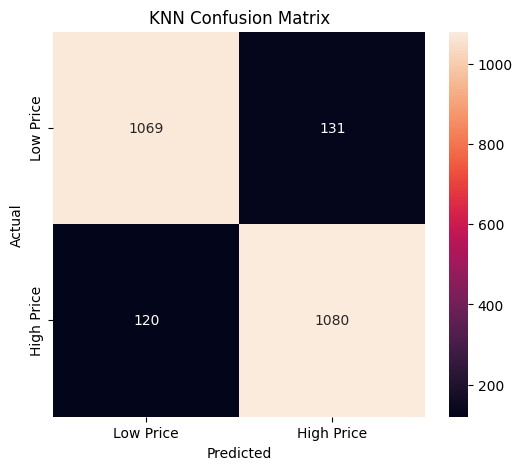

In [ ]:
cm = confusion_matrix(
    y_test_c,
    knn_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Low Price', 'High Price'],
    yticklabels=['Low Price', 'High Price']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")

plt.show()

In [ ]:
classification_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN'
    ],
    'Accuracy': [
        logistic_accuracy,
        knn_accuracy
    ]
})

classification_results

,Model,Accuracy
0,Logistic Regression,0.885417
1,KNN,0.895417


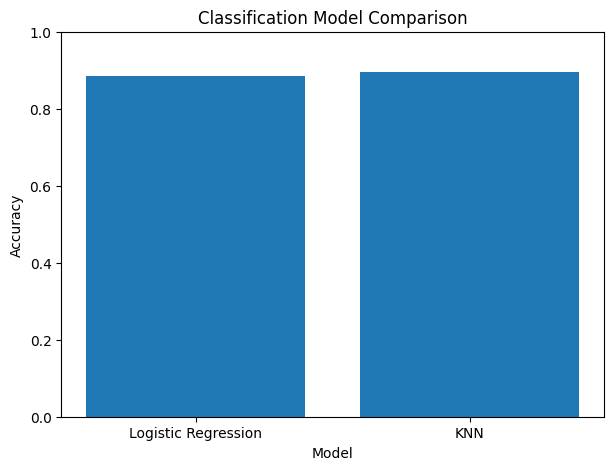

In [ ]:
plt.figure(figsize=(7,5))

plt.bar(
    classification_results['Model'],
    classification_results['Accuracy']
)

plt.ylim(0,1)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Classification Model Comparison")

plt.show()

In [ ]:
# Create a fresh preprocessor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

categorical_features = [
    'parking'
]

numerical_features = [
    'bhk',
    'area_sqft'
]

fresh_preprocessor = ColumnTransformer(
    transformers=[
        ('cat',
         OneHotEncoder(handle_unknown='ignore'),
         categorical_features),

        ('num',
         StandardScaler(),
         numerical_features)
    ]
)

fresh_linear_model = Pipeline([
    ('preprocessor', fresh_preprocessor),
    ('model', LinearRegression())
])

fresh_linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
import pandas as pd
new_property = pd.DataFrame({
    'bhk': [3],
    'area_sqft': [1500],
    'parking': [1]
})

predicted_price = fresh_linear_model.predict(new_property)

print("Predicted Property Price: ₹", round(predicted_price[0], 2))

Predicted Property Price: ₹ 28133796.66


In [ ]:
predicted_category = logistic_model.predict(new_property)

print("Predicted Price Category:",
      predicted_category[0])

Predicted Price Category: High Price


In [ ]:
import pandas as pd

new_property = pd.DataFrame({
    'bhk': [5],
    'area_sqft': [3000],
    'parking': [1]
})

predicted_price = fresh_linear_model.predict(new_property)

print("========== LUXURY PROPERTY ==========")
print("BHK          : 5")
print("Area (sqft)  : 3000")
print("Parking      : Yes")
print("--------------------------------")
print("Predicted Price: ₹", round(predicted_price[0], 2))

predicted_category = logistic_model.predict(new_property)

print("Price Category:", predicted_category[0])

========== LUXURY PROPERTY ==========
BHK          : 5
Area (sqft)  : 3000
Parking      : Yes
--------------------------------
Predicted Price: ₹ 73265538.58
Price Category: High Price
